In [3]:
import os
import sys
from pathlib import Path

# Notebooks run from the notebooks/ folder, so move to the project root
root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(root)
sys.path.insert(0, str(root))

import pandas as pd
from app.data.validation import validate_csv_structure
from app.data.preprocessing import preprocess_transactions

raw = validate_csv_structure("data/sample_transactions.csv")
df, report = preprocess_transactions(raw)
print(report)
df.head()

{'total_rows_after_cleaning': 37, 'rows_dropped': 0}


,date,description,amount
0,2026-01-03,Swiggy Order,-450.00
1,2026-01-04,Salary Credit,55000.00
2,2026-01-05,Uber Ride,-220.50
3,2026-01-06,DMart Groceries,-1850.75
4,2026-01-08,Netflix Subscription,-499.00


In [4]:
print("Shape:", df.shape)
print("\nColumn types:\n", df.dtypes)
print("\nMissing values:\n", df.isna().sum())
print("\nDate range:", df["date"].min(), "to", df["date"].max())
print("\nAmount summary:\n", df["amount"].describe())

Shape: (37, 3)

Column types:
 date           datetime64[us]
description               str
amount                float64
dtype: object

Missing values:
 date           0
description    0
amount         0
dtype: int64

Date range: 2026-01-03 00:00:00 to 2026-03-28 00:00:00

Amount summary:
 count       37.000000
mean      1192.777027
std      17276.222846
min     -28500.000000
25%      -2100.000000
50%       -950.000000
75%       -450.000000
max      56000.000000
Name: amount, dtype: float64


Matplotlib is building the font cache; this may take a moment.


Total income:   166000.0
Total expenses: -121867.25

Largest expenses:
         date        description   amount
28 2026-03-08  Electronics Store -28500.0
8  2026-01-18       College Fees -15000.0
12 2026-01-28       Rent Payment -12000.0
23 2026-02-22       Rent Payment -12000.0
32 2026-03-18       Rent Payment -12000.0


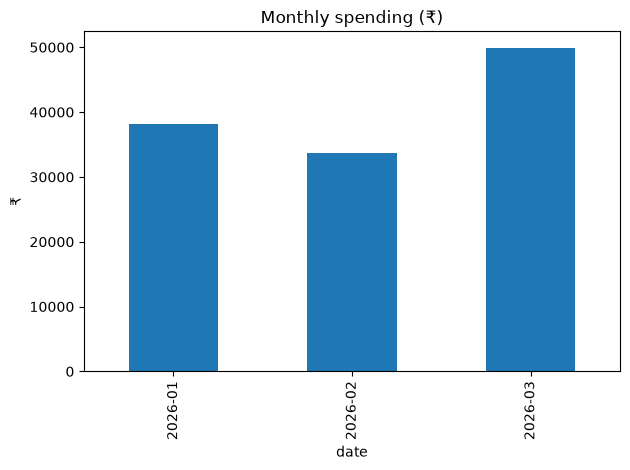

In [6]:
import matplotlib.pyplot as plt

expenses = df[df["amount"] < 0].copy()
income = df[df["amount"] > 0]

print("Total income:  ", income["amount"].sum())
print("Total expenses:", expenses["amount"].sum())
print("\nLargest expenses:")
print(expenses.nsmallest(5, "amount")[["date", "description", "amount"]])

monthly = expenses.groupby(expenses["date"].dt.to_period("M"))["amount"].sum().abs()
monthly.plot(kind="bar", title="Monthly spending (₹)")
plt.ylabel("₹")
plt.tight_layout()
plt.show()